In [17]:
from langgraph.prebuilt import create_react_agent
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from langchain_community.vectorstores import FAISS
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_community.document_loaders import WebBaseLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import StateGraph, END
from typing import Annotated, TypedDict, Sequence

from langchain_core.messages import HumanMessage, SystemMessage, AIMessage, BaseMessage
from langgraph.graph.message import add_messages

In [18]:
docs = WebBaseLoader("https://lilianweng.github.io/").load()
splitter = RecursiveCharacterTextSplitter(
    chunk_size=500, chunk_overlap=25
)

chunks = splitter.split_documents(docs)

embeddings = OpenAIEmbeddings()
vectorsstore = FAISS.from_documents(embedding=embeddings, documents=docs)

retriever = vectorsstore.as_retriever()
retriever


VectorStoreRetriever(tags=['FAISS', 'OpenAIEmbeddings'], vectorstore=<langchain_community.vectorstores.faiss.FAISS object at 0x135c2b610>, search_kwargs={})

In [19]:
def retriever_tool_func(query:str):
    response = retriever.invoke(query)
    return "\n\n".join([doc.page_content for doc in response])

In [20]:
from langchain_community.tools import Tool

retriever_tool = Tool(
    name="RagRetriever",
    description="This tool useful for fetch relavent info",
    func=retriever_tool_func
)

retriever_tool.name

'RagRetriever'

In [21]:
wiki_tool  = WikipediaQueryRun(api_wrapper = WikipediaAPIWrapper())
wiki_tool.name

'wikipedia'

In [41]:
tools = [retriever_tool, wiki_tool]
llm = ChatOpenAI(model="gpt-4o-mini")
from langchain_core.messages import HumanMessage
from langgraph.prebuilt import create_react_agent

agent = create_react_agent(model=llm, tools=tools)



/var/folders/12/zt3xcr4d475gzrfc596w39xm0000gn/T/ipykernel_73719/1542842356.py:6: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  agent = create_react_agent(model=llm, tools=tools)


In [42]:
class State(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]

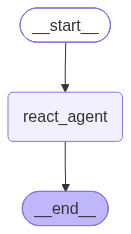

In [43]:
builder = StateGraph(State)

builder.add_node("react_agent", agent)
builder.set_entry_point("react_agent")
builder.add_edge("react_agent", END)


graph = builder.compile()
graph

In [44]:
if __name__ == "__main__":
    user_query = "What is an agent loop, and how does Wikipedia describe it?"
    state = {"messages": [HumanMessage(content=user_query)]}

    result = graph.invoke(state)

    print(result["messages"][-1].content)

An **agent loop** generally refers to a feedback mechanism within AI systems, where an agent interacts with its environment, processes the results, and uses that information to improve its future performance or decision-making. 

### Wikipedia Description:
Wikipedia describes an **AI agent** as an artificial intelligence program capable of making decisions, pursuing goals, and taking actions independent of human intervention. Key features include goal-directed behavior, the ability to use external tools, interact with and modify the environment, and autonomously perform multi-step tasks. Typically, the control flow in these systems is often driven by large language models (LLMs). 

The term also relates to the concept of an **agent harness**, which is the software infrastructure that enables a LLM to function as an AI agent. It manages various aspects like tool use, memory, state persistence, and feedback loops, essentially providing the necessary scaffolding for the model's operations